# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [4]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Connect to 'enterprise_database.db'
# 2. Write a SQL query (using Window Functions or Subqueries) to get the most
#    recent status for each user.
# 3. Only keep users whose latest status is 'Active'.
# 4. Load the result into a Pandas DataFrame called 'df_active_users'.

con = sqlite3.connect("enterprise_database (1).db")

query = """
SELECT user_id, name, status, updated_at FROM (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC) AS rn
    FROM users
)
WHERE rn = 1 AND status = 'Active'
"""

df_active_users = pd.read_sql(query, con)
df_active_users.shape


(14183, 4)

In [7]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

# 1. Load 'server_logs.txt' into a DataFrame.
# 2. Drop any rows where the log contains the word "ERROR".
# 3. Use Pandas string methods (.str.extract()) or Python Regex to pull the
#    Date, User ID, Product ID, and Euro Value out of the raw text string.
# 4. Save this cleaned data to a new DataFrame called 'extracted_data'.

logs = pd.read_csv("server_logs (1).txt")

logs = logs[~logs["Raw_Server_Log"].str.contains("ERROR", na=False)]

extracted_data = logs["Raw_Server_Log"].str.extract(
    r'\[(\d{4}-\d{2}-\d{2}).*?"u":\s*"(U-\d+)".*?"item_code":\s*"(PRD-\d+)".*?"eur_val":\s*([\d.]+)'
)
extracted_data.columns = ["Date", "User_ID", "Product_ID", "Euro_Value"]

extracted_data["Date"] = pd.to_datetime(extracted_data["Date"])
extracted_data["Euro_Value"] = extracted_data["Euro_Value"].astype(float)

extracted_data.shape

extracted_data.head()

,Date,User_ID,Product_ID,Euro_Value
0,2023-03-15,U-19484,PRD-874,3404.44
2,2023-05-09,U-18932,PRD-905,3406.21
3,2023-10-21,U-15882,PRD-284,164.08
4,2023-01-10,U-22781,PRD-665,26.80
5,2023-05-23,U-13348,PRD-589,4964.77


In [8]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
# 2. Handle the missing weekend data using a method like .fillna(method='ffill')
#    so Friday's rate rolls over to Saturday and Sunday.
# 3. Merge your cleaned logs with the exchange rates by Date.
# 4. Merge that result with your active SQL users by User ID.
# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate).
# 6. Save the final merged table as 'df_final'.

# 1. Load the exchange rates
rates = pd.read_csv("daily_exchange_rates (1).csv", parse_dates=["Date"])

# 2. Fill the weekend gaps: Friday's rate rolls forward to Saturday and Sunday
rates["EUR_to_USD"] = rates["EUR_to_USD"].ffill()

# 3. Join the transactions to the rates by date
df_merged = extracted_data.merge(rates, on="Date", how="left")

# 4. Join with the active users only
df_final = df_merged.merge(
    df_active_users[["user_id"]],
    left_on="User_ID", right_on="user_id",
    how="inner"
)

# 5. Calculate revenue in USD
df_final["USD_Revenue"] = df_final["Euro_Value"] * df_final["EUR_to_USD"]

df_final.shape

(53899, 7)

In [9]:
df_merged["EUR_to_USD"].isna().sum()    # should be 0
df_final["USD_Revenue"].sum()           # should be about 148,274,622

np.float64(148274622.90646717)

In [10]:
rates_raw = pd.read_csv("daily_exchange_rates (1).csv", parse_dates=["Date"]).dropna()
without_ffill = extracted_data.merge(rates_raw, on="Date", how="inner")
print(len(extracted_data), len(without_ffill))
print(round(100 * (1 - len(without_ffill) / len(extracted_data)), 1))

94902 67918
28.4


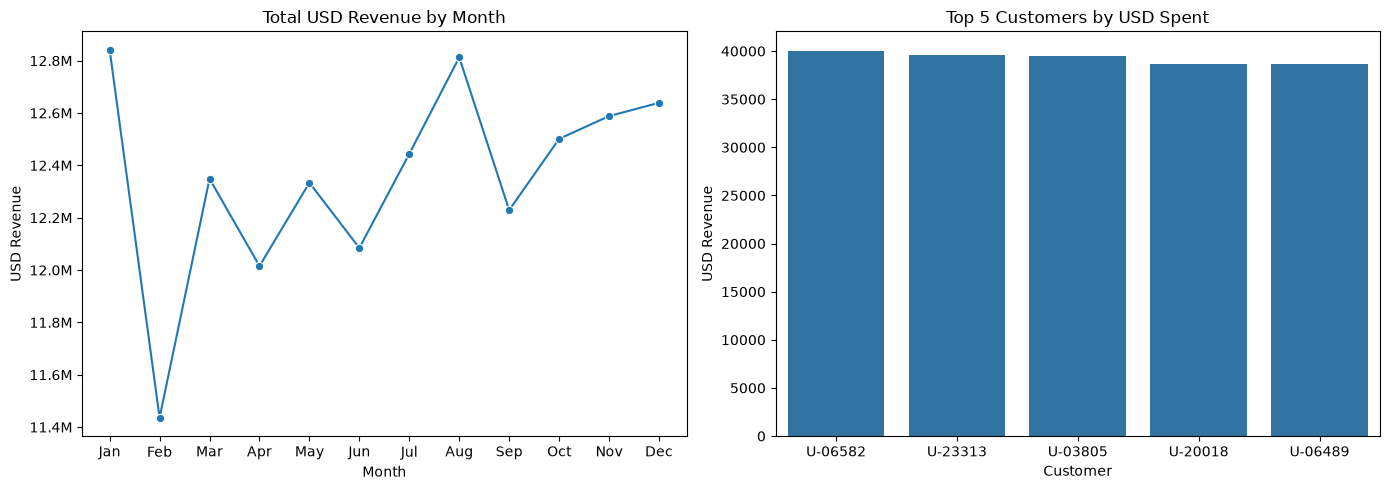

In [11]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

# 1. Group the data in 'df_final' to calculate Total USD Revenue by Month.
# 2. Group the data to find the Top 5 Most Valuable Customers by Total USD spent.
# 3. Use Matplotlib or Seaborn to generate two charts side-by-side:
#    - Chart 1: A Line Chart or Bar Chart showing Revenue by Month.
#    - Chart 2: A Bar Chart showing the Top 5 Customers.
# 4. Ensure your charts have titles, clean axes, and are easy to read.

# 1. Total USD revenue by month
monthly_rev = (df_final.groupby(df_final["Date"].dt.to_period("M"))["USD_Revenue"]
                       .sum().reset_index())
monthly_rev["Date"] = monthly_rev["Date"].dt.strftime("%b")

# 2. Top 5 customers by total USD spent
top5 = (df_final.groupby("User_ID")["USD_Revenue"]
                .sum().nlargest(5).reset_index())

# 3. Two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=monthly_rev, x="Date", y="USD_Revenue", marker="o", ax=axes[0])
axes[0].set_title("Total USD Revenue by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("USD Revenue")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f}M")

sns.barplot(data=top5, x="User_ID", y="USD_Revenue", ax=axes[1])
axes[1].set_title("Top 5 Customers by USD Spent")
axes[1].set_xlabel("Customer")
axes[1].set_ylabel("USD Revenue")

plt.tight_layout()
plt.show()
